# 5.1 ข้อมูลนำเข้า การฉายประชากร และตัวหารสามแบบ

สมุดบันทึกนี้แสดง **สัญญาข้อมูลนำเข้า** จากบทที่ 4 การฉายประชากร การเข้า–ออกของแพทย์ และดัชนีความรับผิดชอบ P, S และ N-STD
ทุกผลลัพธ์สร้างด้วย `python -m chapter5.build --inputs` (ฟังก์ชัน `chapter5.pipeline.stage_inputs`) สมุดบันทึกนี้เรียกฟังก์ชันเดียวกันและแสดงตารางกลาง

| ส่วน | คำถาม |
|---|---|
| A | ข้อมูลใดพร้อม ข้อมูลใดขาด และแผนจึงมีสถานะใด |
| B | ประชากร 76 จังหวัดจะเปลี่ยนอย่างไรถึง พ.ศ. 2583 และแบบจำลองประชากรแม่นแค่ไหนเมื่อตรวจย้อนหลัง |
| C | แพทย์ออกและกลับเข้าในอัตราเท่าใด |
| D | ตัวหารสามแบบต่างกันอย่างไร และ M5 ยังอยู่ในช่วงข้อมูลที่ใช้ประมาณหรือไม่ |

In [1]:
import sys
from pathlib import Path
_root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config" / "chapter5.toml").exists())
sys.path.insert(0, str(_root / "src"))
import json
import numpy as np
import pandas as pd
from IPython.display import display, Image
pd.options.display.max_columns = 40
pd.options.display.width = 200
from chapter5 import config as C, pipeline as PL, allocation as AL, simulation as SIM, responsibilities as R
S = C.load()
D = S.dirs()
tab = lambda n, f="tables": pd.read_csv(D[f] / f"{n}.csv", encoding="utf-8-sig")
print("scenario:", S.name, "| config_hash:", S.hash())

scenario: canonical | config_hash: e0082b9acf0428bc


## ค่าตั้งที่ใช้จริง
แต่ละค่ามีสถานะที่มา: *observed/estimated* (จากข้อมูล), *illustrative* (ตัวอย่างที่ปรับได้), *policy* (ผู้กำหนดนโยบายต้องเลือก), *convention* (ข้อตกลงของแบบจำลอง)

In [2]:
cfg = S.effective_table()
display(cfg[cfg.provenance.isin(['illustrative', 'policy', 'estimated'])])

,key,value,provenance,unit,overridden
20,demography.migration_scenarios,"{""low"": 0.5, ""central"": 1.0, ""high"": 1.5}",illustrative,,False
26,supply.annual_path,2000,illustrative,accepted starts per year (managed 76-province ...,False
28,supply.national_graduates,3000,illustrative,graduates per year (national),False
29,supply.licensing,0.95,illustrative,,False
30,supply.participation,0.95,illustrative,,False
31,supply.managed_share,0.74,illustrative,,False
33,supply.completion,0.93,illustrative,,False
34,supply.intake_2026_onwards,3300,illustrative,,False
35,supply.graduates_in_pipeline,"[3000, 3000, 3050, 3100, 3150, 3200]",illustrative,,False
41,departures.workload_departure_elasticity,0.104326,estimated,"log-log, resignations on OP visits per physician",False


In [3]:
r = PL.stage_inputs(S)   # rebuilds the input tables (about 5 s); identical to the build command
ctx = r['ctx']

## A. สัญญาข้อมูลนำเข้าและความพร้อมของข้อมูล
ทุกไฟล์จากบทที่ 4 ถูกบันทึก SHA-256 และ M5 ถูกประมาณซ้ำด้วยโค้ดของบทที่ 4 แล้วตรวจว่าตรงกับตารางที่ส่งออก

In [4]:
display(tab('T5_INPUT_CONTRACT', 'validation'))
display(tab('T5_DATA_READINESS'))

,artifact,exists,sha256,bytes
0,data/processed/province_key.csv,True,a5d40fe056aae6d8da2692bb8e92e060a4c87ef7b6f7e8...,3565.0
1,data/processed/workforce_province.csv,True,125884d089a1a32564249a2f53074978e98918acb0a4c0...,1725244.0
2,data/processed/population_single_age.csv,True,0d759bbcda47aaacc10beb3bddb3150c80d10108211823...,3616237.0
3,data/processed/population_registers.csv,True,21d0589b0a882d23cf6ffd4757ebdc5e09d13fcc2d276d...,92695.0
4,data/processed/services_province.csv,True,2f982d97379674b7385193be1a5f0b970b4641f5b4cc7d...,1001789.0
5,data/processed/casemix_province.csv,True,1d066f6acc8fc63498ed04f707dcd8dfdfdb3a1b3cf41c...,37136.0
6,data/processed/hdc_indicators.csv,True,c802bde3fb64a7efe228cbe65224a62dcd374d8b921285...,365880.0
7,data/processed/gpp_province.csv,True,5300e74c620ade7f1063a5b670be2f73cabf4e7a2b5b81...,57091.0
8,data/processed/flow_events.csv,True,7f2b3b27d849f256f17d62e939c6134b04e1791e3fdc50...,8505556.0
9,data/processed/bod_province.csv,True,952ec5541963f97af01cc3632cf4614981f757054d21c2...,2752102.0


,input,minimum_content,status,used_in_chapter5,fallback_if_absent,affected_claims
0,Baseline physician stock,"province, employer scope, reference date, count",partial: MOPH-wide headcount (HRR report year ...,"MOPH physicians, 76 provinces, 2025 = 22,685 (...",broader-scope stock used as an explicitly labe...,"every plan is exploratory_policy_scenario, not..."
1,Historical workforce,comparable annual provincial stocks and breaks,"available 2013-2025 (break 2016, 2020)",stock-flow backtest FY2021-2025; not used to i...,-,backtest only
2,Entries/exits,"category x province x year, boundary and dupli...","partial: HROPS events FY2017-2025 (OPS), not u...",hazards per opening-stock person-year FY2021-2...,event-to-person assumption stated; internal tr...,departure expectations; transfer routes are pr...
3,Population,baseline age/sex counts and register definitions,available: DOPA single-year age x sex 2013-2025,"civil_age register (Thai nationals, regular re...",-,-
4,Demographic projection inputs,"official provincial projection or survival, fe...","absent: no official provincial projection, no ...",Hamilton-Perry cohort-change projection (death...,request NESDC/IPSR provincial projection and D...,population and age paths
5,Entitlement register,"province, reference date, scheme/age/sex",available: NHSO December snapshots 2010-2025,province ratio NHSO/civil held at 2025 with 20...,-,P entitlement variant
6,Service data,"OP visits, IP days, AdjRW, universe, breaks",available: HRR RH+GH+CH 2013-2025; case-mix FY...,constant-rate benchmark chosen by backtest; CO...,-,S family
7,M5 package,"coefficients, covariance, transforms, referenc...",available: refitted and matched to T423_M5_COE...,"N-STD, resource-responsive services, N-FB",-,N family; feedback experiment
8,Future disease/economic paths,defensible projections or explicit assumptions,absent: 4 years of aggregate diagnosed prevale...,fixed-2025 prevalence (central); bounded trend...,-,N-STD growth
9,Modeled burden of disease,"provincial burden by cause, age and sex; sever...","partial: BOD Thailand 2022, 174 causes x 8 age...",B family: projected age groups x 2022 age-spec...,further subnational BOD rounds would allow tre...,B family (age-specific rates fixed at 2022)


## B. ประชากร
Hamilton–Perry: อัตราส่วนการเปลี่ยนแปลงของรุ่น (CCR) รวมการรอดชีพกับการย้ายถิ่นสุทธิไว้ด้วยกัน การเกิดใช้อัตราส่วนเด็กต่อสตรี 15–49 ปี
$P_{p,a+1,s,t+1}=CCR_{p,a,s}P_{p,a,s,t}$ และปรับทุกปีให้ผลรวม 77 จังหวัดเท่ากับการฉายระดับประเทศ (กรุงเทพฯ เป็นขอบเขตภายนอกของการจัดสรร)

In [5]:
display(tab('T5_POP_BACKTEST', 'validation'))
pop = tab('T5_POP_PROJECTION'); p76 = pop[pop.prov_code.isin(ctx.provs)]
display(p76.groupby(['scenario', 'year'])[['population', 'n3_60+']].sum().unstack(0).iloc[[0, 5, 10, 15]])

,method,base_year,target_year,provinces,mape_total_pct,medape_total_pct,max_ape_total_pct,national_76_error_pct,mae_share60_pp,median_dissimilarity_index
0,hamilton_perry_national_control,2019,2025,76,1.108112,0.877467,4.936297,1.103781,0.275685,0.011711
1,hamilton_perry_unconstrained,2019,2025,76,1.218959,0.994843,5.073629,1.221368,0.290585,0.011938
2,no_change_2019,2019,2025,76,2.227500,1.808269,7.455456,0.246152,4.718477,0.064641
3,linear_trend_totals_2013_2019,2019,2025,76,2.618441,2.525567,5.342860,2.624402,NaN,NaN


population                                    n3_60+                            
scenario       central          high           low       central          high           low
year                                                                                        
2025      5.931618e+07  5.931618e+07  5.931618e+07  1.277726e+07  1.277726e+07  1.277726e+07
2030      5.853572e+07  5.856182e+07  5.850999e+07  1.490837e+07  1.490910e+07  1.490736e+07
2035      5.724065e+07  5.729183e+07  5.719046e+07  1.657784e+07  1.658596e+07  1.656871e+07
2040      5.540678e+07  5.548119e+07  5.533465e+07  1.770280e+07  1.772308e+07  1.768037e+07

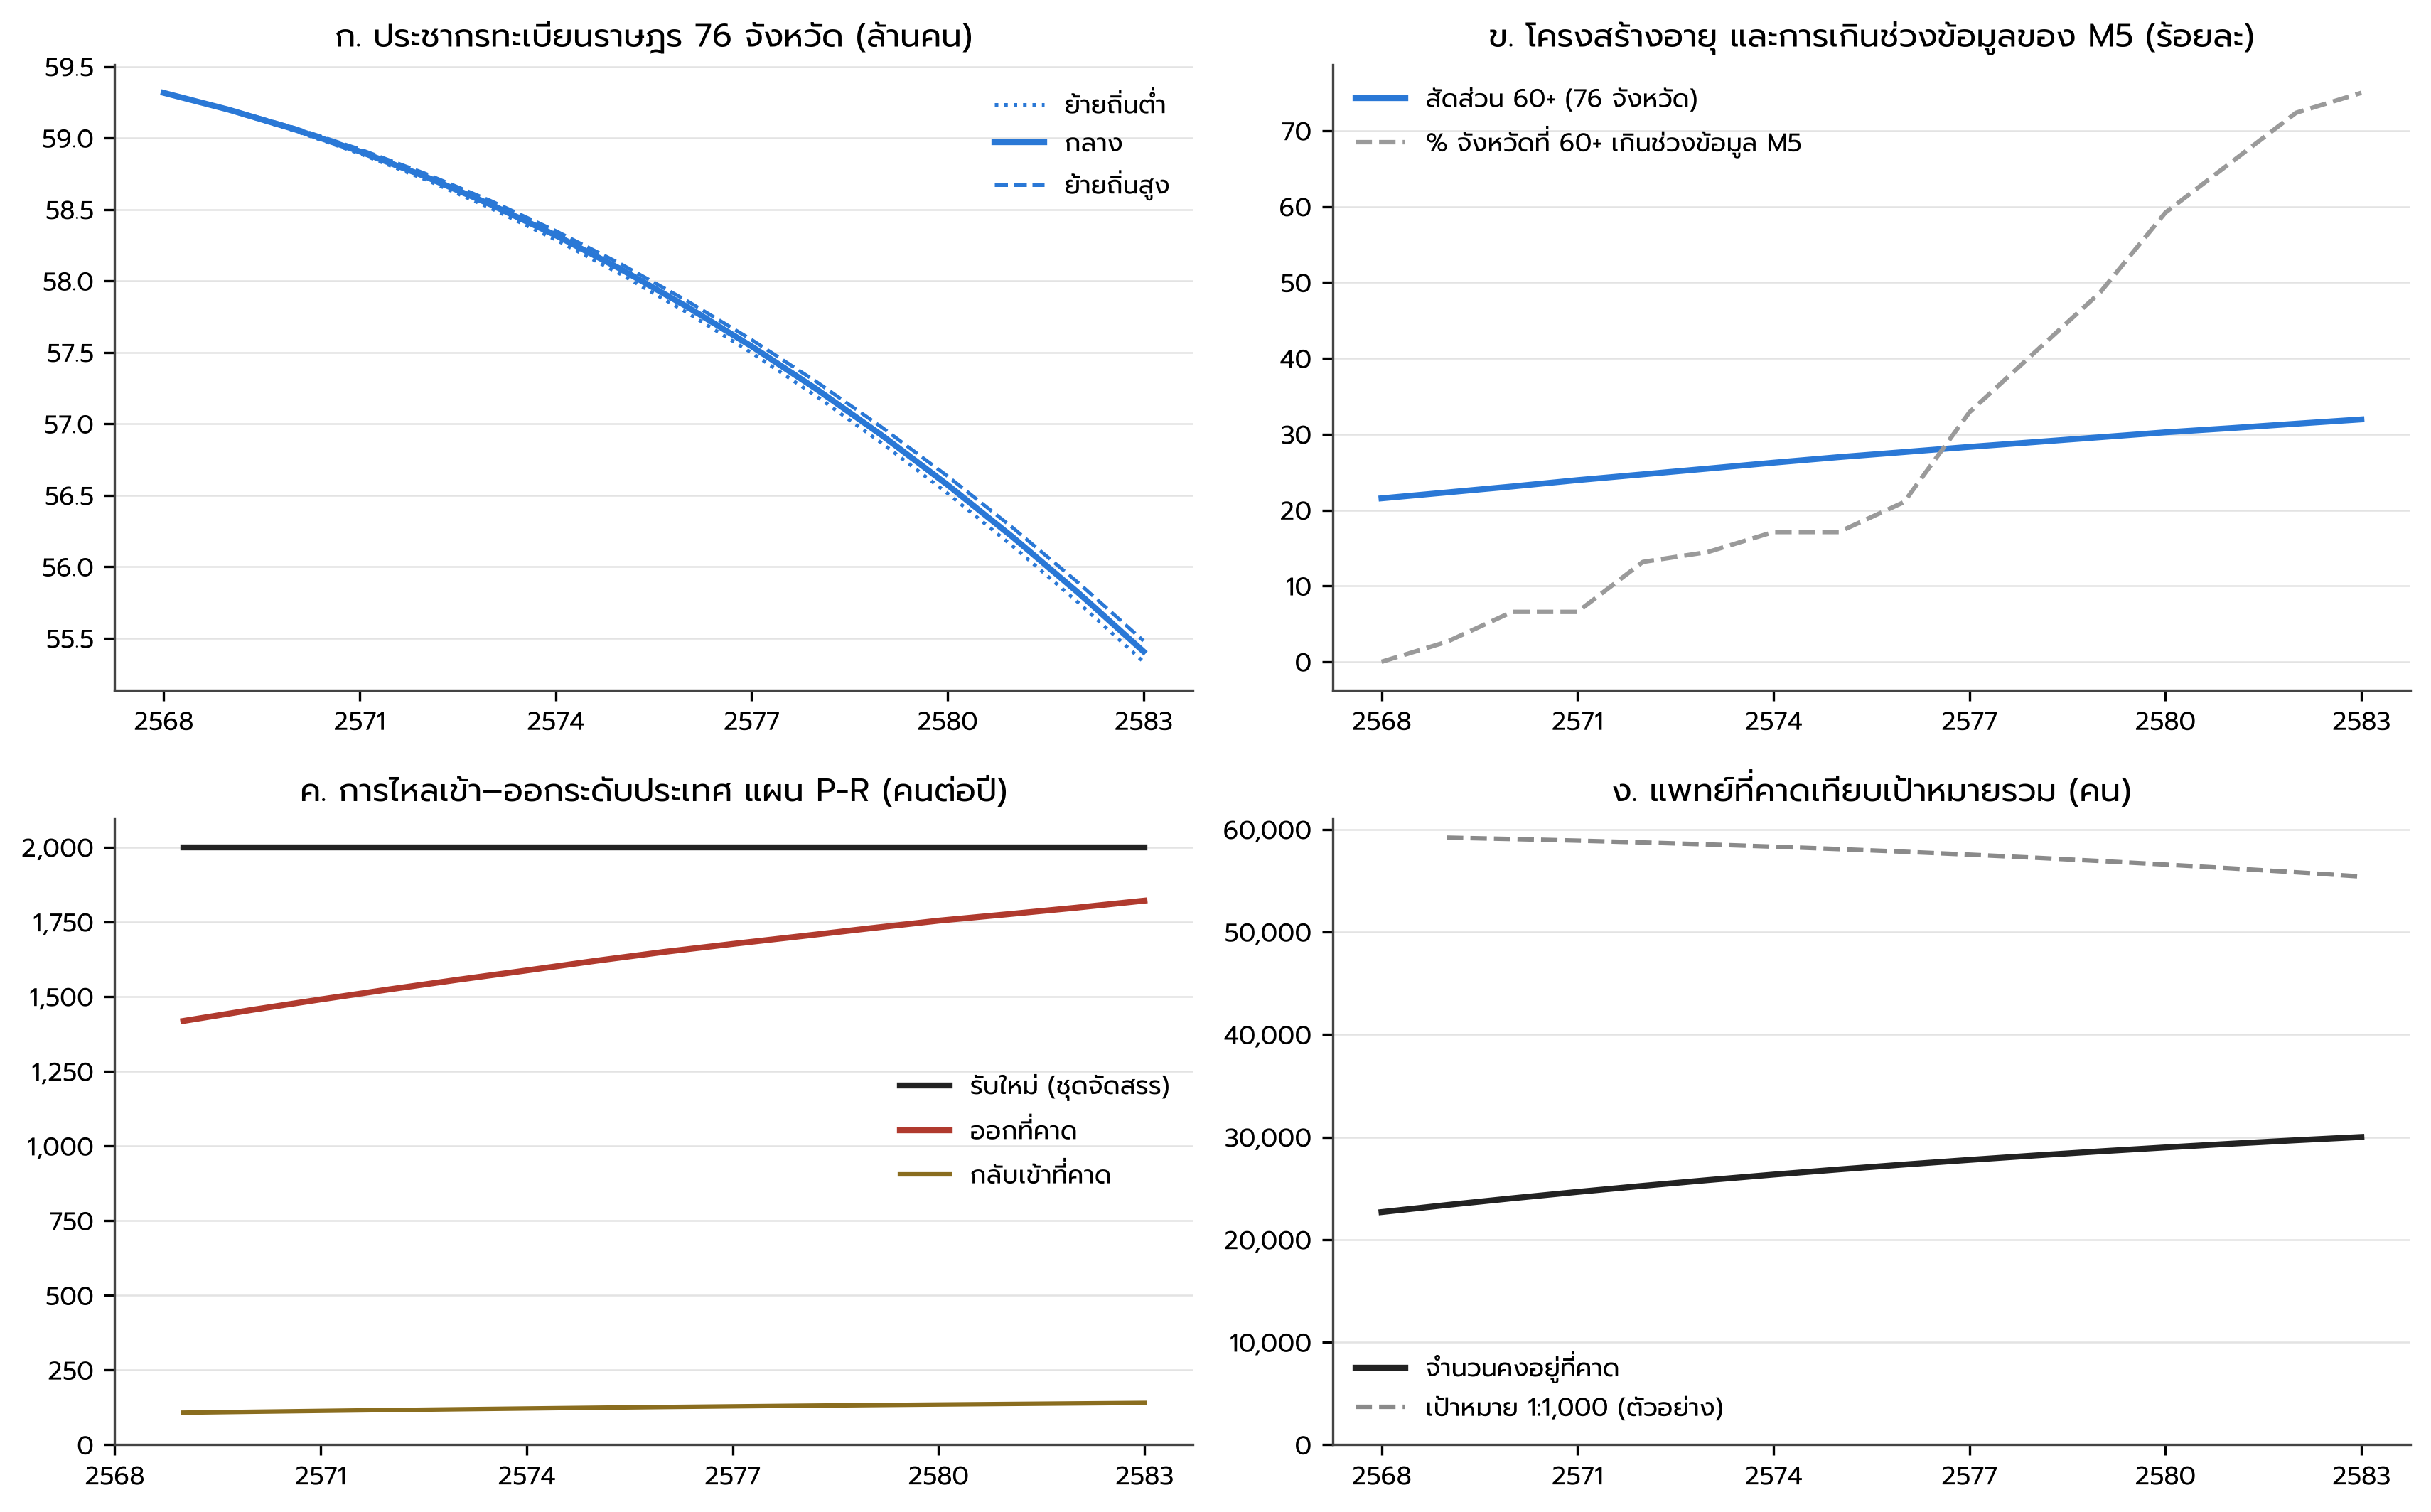

In [6]:
display(Image(str(D['figures'] / 'F52_POPULATION_AND_SUPPLY.png')))

## C. การเข้า–ออก
อัตราเหตุการณ์ต่อบุคลากรตั้งต้น (ปีงบ 2564–2568) ถูกรวมกำลังแบบ empirical Bayes เข้าหาค่าของเขตสุขภาพ แล้วแปลงเป็นความน่าจะเป็น $d=1-\exp(-\sum_k h_k)$ ซึ่งไม่เกิน 1 และไม่นับคนเดียวกันออกสองสาเหตุ

In [7]:
fr = tab('T5_FLOW_RATES')
display(fr.groupby('cause')[['events', 'exposure']].sum().assign(per100=lambda z: 100 * z.events / z.exposure))
display(tab('T5_NATIONAL_STOCK_FLOW', 'validation'))
display(tab('T5_STOCK_FLOW_BACKTEST', 'validation'))

,events,exposure,per100
cause,,,
death,45.0,101596.0,0.044293
disciplinary,23.0,101596.0,0.022639
recruitment_hiring,10462.0,101596.0,10.297650
reinstatement,457.0,101596.0,0.449821
resignation,5610.0,101596.0,5.521871
retirement,764.0,101596.0,0.751998
transfer_in,22.0,101596.0,0.021654
transfer_out,209.0,101596.0,0.205717


,fiscal_year,stock_prev,stock,recruitment,reentry,exits,d_stock,net_recorded,residual
0,2017,16799.0,19390.0,2152.0,86.0,1184.0,2591.0,1054.0,1537.0
1,2018,19390.0,20443.0,2034.0,81.0,1117.0,1053.0,998.0,55.0
2,2019,20443.0,21481.0,2108.0,75.0,1127.0,1038.0,1056.0,-18.0
3,2020,21481.0,18327.0,2167.0,100.0,1057.0,-3154.0,1210.0,-4364.0
4,2021,18327.0,19901.0,2099.0,114.0,1066.0,1574.0,1147.0,427.0
5,2022,19901.0,20533.0,1951.0,76.0,1282.0,632.0,745.0,-113.0
6,2023,20533.0,21276.0,2005.0,94.0,1509.0,743.0,590.0,153.0
7,2024,21276.0,21559.0,2218.0,86.0,1467.0,283.0,837.0,-554.0
8,2025,21559.0,22685.0,2189.0,109.0,1327.0,1126.0,971.0,155.0


,year,simulated,observed,residual,mape_province_pct,share_provinces_abs_error_gt10pct
0,2021,19353.563110,19901.0,547.436890,5.372031,0.092105
1,2022,20174.665431,20533.0,358.334569,6.131347,0.197368
2,2023,21005.346141,21276.0,270.653859,8.273382,0.328947
3,2024,21999.597791,21559.0,-440.597791,11.105694,0.460526
4,2025,22908.249933,22685.0,-223.249933,11.267252,0.421053


## D. ตัวหารสามแบบ
ทุกดัชนีแปลงเป็นหน่วยเทียบเท่าประชากรด้วยสเกลคงที่ปี 2568 เพื่อให้การเติบโตของภาระหลังจากนั้นยังคงอยู่

In [8]:
display(tab('T5_DENOMINATOR_REGISTRY'))
ix = ctx.idx
display(ix.groupby('year')[['D_P', 'D_Pent', 'D_S', 'D_N']].sum().iloc[[0, 5, 10, 15]])
display(tab('T5_SERVICE_BACKTEST', 'validation'))
display(tab('T5_M5_SUPPORT_BY_YEAR', 'validation'))

,family,index,raw,raw_unit,normalization,scale,dynamic_through,fixed,scenario,interpretation
0,P,D_P,"projected civil-register population (DOPA, Tha...",persons,none (equals raw),1.000000,population projection only,-,"{""demog"": ""central"", ""departures"": ""pooled"", ""...",every resident counts equally
1,P_ent,D_Pent,projected entitlement population (NHSO ratio x...,persons,x P_total_2025 / Ent_total_2025,0.973262,civil projection; ratio held at 2025,province ratio NHSO/civil,"{""demog"": ""central"", ""departures"": ""pooled"", ""...","administrative entitlement, not extra residents"
2,S,D_S,10 min x OP visits + 100 min x AdjRW (observed...,minutes (illustrative weights),fixed 2025 scale,0.024258,population x benchmark service rate,2025 provincial service rates,"{""demog"": ""central"", ""departures"": ""pooled"", ""...",services entering the current system; carries ...
3,N-STD,D_N,same weights applied to M5 standardized OP and...,minutes (illustrative weights),fixed 2025 scale,0.026180,"population, age composition, recorded morbidit...","economy, beds, physicians, nurses, year effect...","{""demog"": ""central"", ""departures"": ""pooled"", ""...",M5_standardized_need_proxy; not normative need
4,B,D_B,sum over 8 age groups of projected persons x t...,expected DALYs per year,fixed 2025 scale,3.066849,population size and age structure,provincial age-specific DALY rates held at 202...,"{""demog"": ""central"", ""departures"": ""pooled"", ""...",expected_burden: modeled health loss independe...
5,B-yld,D_Byld,the same with age-specific YLD rates,expected YLDs per year,fixed 2025 scale,14.513327,population size and age structure,provincial age-specific YLD rates held at 2022,"{""demog"": ""central"", ""departures"": ""pooled"", ""...",morbidity-only sensitivity of B
6,B-asr,D_Basr,projected civil population x age-standardized ...,age-standardized DALY-equivalents,fixed 2025 scale,4.076185,population size only,provincial age-standardized rate held at 2022,"{""demog"": ""central"", ""departures"": ""pooled"", ""...",excess burden only (age removed); sensitivity ...


,D_P,D_Pent,D_S,D_N
year,,,,
2025,5.931618e+07,5.931618e+07,5.931617e+07,5.931617e+07
2030,5.853572e+07,5.854797e+07,5.840582e+07,5.925375e+07
2035,5.724065e+07,5.726515e+07,5.697998e+07,5.797912e+07
2040,5.540678e+07,5.544292e+07,5.501654e+07,5.531648e+07


,outcome,method,n,mape_pct,medape_pct,cutoffs,best_mape,chosen,selection_rule
0,adjrw,constant_last,228,8.686271,7.802491,2,False,True,min MAPE; non-persistence needs >= 3 cutoffs
1,adjrw,mean_last3,228,14.651482,15.491245,2,False,False,min MAPE; non-persistence needs >= 3 cutoffs
2,adjrw,trend_last5_damped,228,6.666772,5.488382,2,True,False,min MAPE; non-persistence needs >= 3 cutoffs
3,ip_moph,constant_last,608,10.769994,5.519135,4,True,True,min MAPE; non-persistence needs >= 3 cutoffs
4,ip_moph,mean_last3,608,11.233818,7.058658,4,False,False,min MAPE; non-persistence needs >= 3 cutoffs
5,ip_moph,trend_last5_damped,608,11.844001,5.774438,4,False,False,min MAPE; non-persistence needs >= 3 cutoffs
6,op_moph,constant_last,608,11.495103,6.754032,4,True,True,min MAPE; non-persistence needs >= 3 cutoffs
7,op_moph,mean_last3,608,12.929478,9.452900,4,False,False,min MAPE; non-persistence needs >= 3 cutoffs
8,op_moph,trend_last5_damped,608,12.064979,6.723534,4,False,False,min MAPE; non-persistence needs >= 3 cutoffs


,year,share_extrapolation,share_age60_out,share_joint_out
0,2025,0.000000,0.000000,0.000000
1,2026,0.026316,0.026316,0.000000
2,2027,0.078947,0.065789,0.026316
3,2028,0.105263,0.065789,0.026316
4,2029,0.157895,0.131579,0.105263
5,2030,0.276316,0.144737,0.210526
6,2031,0.447368,0.171053,0.394737
7,2032,0.565789,0.171053,0.526316
8,2033,0.657895,0.210526,0.618421
9,2034,0.763158,0.328947,0.736842


### ตรวจว่า N-STD ไม่ขึ้นกับจำนวนแพทย์
เปลี่ยนความหนาแน่นแพทย์ที่ป้อนเข้าไปแล้วค่าทำนายแบบอ้างอิงต้องไม่เปลี่ยน

In [9]:
cov, res = ctx.fb._rows(2035)
a = R.m5_rate(ctx.pkg, 'adjrw', cov, res, np.log(np.full(76, 10.)), 2023, reference=True)
b = R.m5_rate(ctx.pkg, 'adjrw', cov, res, np.log(np.full(76, 90.)), 2023, reference=True)
print('max |difference| =', np.abs(a - b).max())

max |difference| = 0.0


### ความยืดหยุ่นของตัวหารป้อนกลับ
$\eta=\partial\ln D/\partial\ln H$; ความหนาแน่นเทียบตัวหารแบบนี้เปลี่ยนตาม $H^{1-\eta}$ และเป้าหมายเพิ่ม $\eta T/H$ คนต่อแพทย์ 1 คน

In [10]:
fe = tab('T5_FEEDBACK_ELASTICITY_2026')
display(fe.groupby('lam')[['eta', 'gain_B']].describe().round(3))

eta                                                  gain_B                                                 
    count   mean    std    min    25%    50%    75%    max  count   mean    std    min    25%    50%    75%    max
lam                                                                                                               
0.0  76.0  0.000  0.000  0.000  0.000  0.000  0.000  0.000   76.0  0.000  0.000  0.000  0.000  0.000  0.000  0.000
0.5  76.0  0.166  0.007  0.145  0.162  0.167  0.171  0.183   76.0  0.455  0.090  0.288  0.390  0.445  0.506  0.879
1.0  76.0  0.334  0.016  0.291  0.326  0.333  0.344  0.377   76.0  0.928  0.133  0.607  0.842  0.922  1.009  1.483